In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [2]:
df=pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")

In [3]:
df.shape

(2000, 8)

In [4]:
df.dtypes

id         int64
prompt    object
A         object
B         object
C         object
D         object
E         object
answer    object
dtype: object

In [5]:
df.head(3)

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C


In [6]:
df.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

In [7]:
df=df.drop('id',axis=1)

In [8]:
df.duplicated().sum()

np.int64(183)

In [9]:
df.duplicated(subset='prompt').sum()

np.int64(242)

In [10]:
df=df.drop_duplicates(subset='prompt',keep='first')

In [11]:
df['prompt_len']=df['prompt'].str.len()
for col in ['A','B','C','D','E']:
    df[f'{col}_len']=df[col].str.len()

def get_overlaps(row):
    prompt_words=set(row['prompt'].split())
    overlaps={}
    for col in ['A','B','C','D','E']:
        option_words=set(row[col].split())
        overlaps[f'{col}_overlap']=len(prompt_words & option_words)
    return pd.Series(overlaps)

overlaps_df=df.apply(get_overlaps,axis=1)
df=pd.concat([df,overlaps_df],axis=1)

Text(0.5, 1.0, 'Answer Distribution')

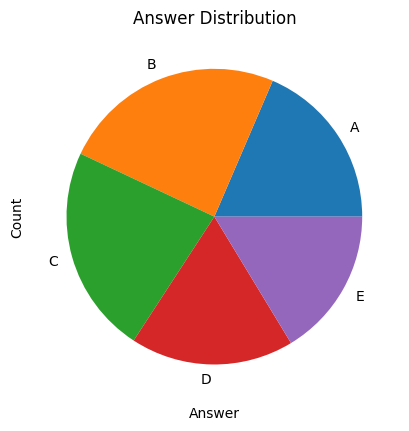

In [12]:
import matplotlib.pyplot as plt

answer=df['answer']
answer.value_counts().sort_index().plot(kind='pie')
plt.xlabel('Answer')
plt.ylabel('Count')
plt.title('Answer Distribution')

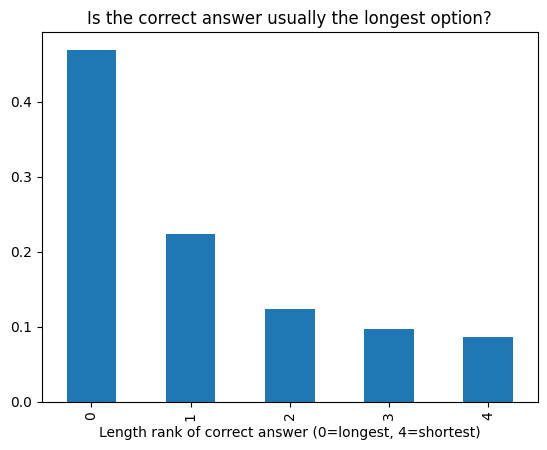

In [13]:
len_cols=['A_len','B_len','C_len','D_len','E_len']
lengths=df[len_cols].values
rank_of_correct=[]

for i,ans in enumerate(df['answer']):
    idx="ABCDE".index(ans)
    row_lengths=lengths[i]
    rank=(row_lengths > row_lengths[idx]).sum()
    rank_of_correct.append(rank)

pd.Series(rank_of_correct).value_counts(normalize=True).sort_index().plot(kind='bar')
plt.xlabel("Length rank of correct answer (0=longest, 4=shortest)")
plt.title("Is the correct answer usually the longest option?")
plt.show()

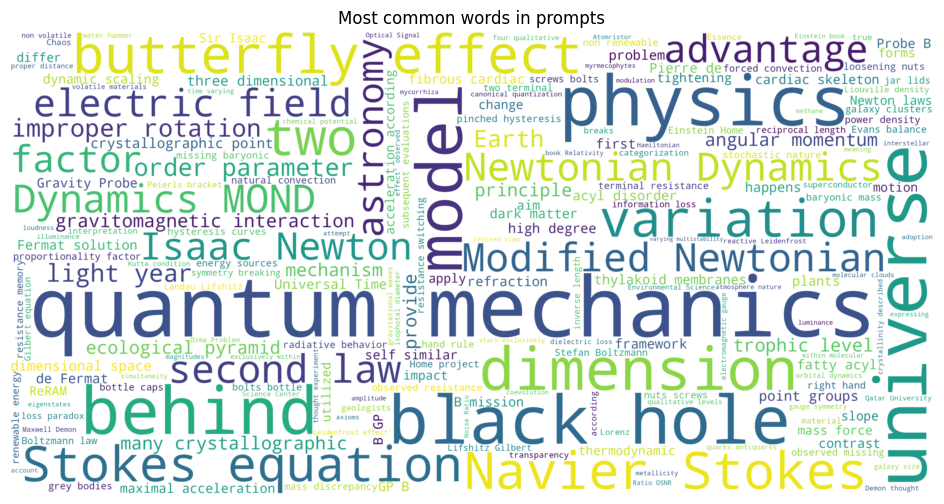

In [14]:
from wordcloud import WordCloud,STOPWORDS
import matplotlib.pyplot as plt

text=" ".join(df['prompt'].tolist())
custom_stopwords=[
    'following', 'listed', 'choices', 'choice', 'options', 'option',
    'correct', 'answer', 'answers', 'statement', 'statements',
    'identify', 'select', 'determine', 'pick', 'choose',
    'context', 'given', 'carefully', 'possible', 'best',
    'among', 'accurately', 'describes', 'describe', 'accurate',
    'based', 'relationship', 'role', 'reason', 'significance',
    'associated', 'used', 'term', 'distinction', 'defined', 'definition',
    'concept', 'measuring', 'origin', 'proposed', 'purpose',
    'focus', 'main', 'formation', 'processes'
]
wc=WordCloud(width=2000,height=1000,background_color='white',scale=2,stopwords=STOPWORDS.union(custom_stopwords),max_words=200).generate(text)

plt.figure(figsize=(12,6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Most common words in prompts")
plt.show()

In [15]:
df=df.drop('answer',axis=1)

In [16]:
from sklearn.model_selection import train_test_split

x_train,x_val,y_train,y_val=train_test_split(df,answer,train_size=0.8,random_state=1,stratify=answer)

In [17]:
def score_to_labels(scores,top1=False):
    labels=[]
    top1_labels=[]
    for score in scores:
        scored=np.argsort(score)[::-1][:3]
        top_3=[chr(65+i) for i in scored]
        labels.append(" ".join(top_3))
        top1_labels.append(chr(65+np.argsort(score)[::-1][0]))
    if not top1:
        return labels
    else:
        return top1_labels

In [18]:
def map_at_3(predictions,ground_truth):
    ap_scores=[]
    for pred, truth in zip(predictions, ground_truth):
        pred_list = pred.split()
        if truth in pred_list:
            ap_scores.append(1.0 / (pred_list.index(truth) + 1))
        else:
            ap_scores.append(0.0)
    return sum(ap_scores) / len(ap_scores)

In [19]:
from sklearn.metrics import accuracy_score,f1_score

def support_metrics(train_scores,val_scores):
    train_acc=accuracy_score(score_to_labels(train_scores,top1=True),y_train)
    val_acc=accuracy_score(score_to_labels(val_scores,top1=True),y_val)
    train_f1=f1_score(score_to_labels(train_scores,top1=True),y_train,average='macro')
    val_f1=f1_score(score_to_labels(val_scores,top1=True),y_val,average='macro')
    return train_acc,val_acc,train_f1,val_f1

In [20]:
def special_option(text):
    text=str(text).lower()
    patterns=['none of the above','all of the above','none of these','all of these','both a and b','both a and c','both b and c','not applicable']
    return int(any(p in text for p in patterns))

In [21]:
for col in ['A','B','C','D','E']:
    x_train[f'{col}_is_special']=x_train[col].apply(special_option)
for col in ['A','B','C','D','E']:
    x_train[f'{col}_is_special']=x_val[col].apply(special_option)
x_train.head(12)

,prompt,A,B,C,D,E,prompt_len,A_len,B_len,C_len,...,A_overlap,B_overlap,C_overlap,D_overlap,E_overlap,A_is_special,B_is_special,C_is_special,D_is_special,E_is_special
1534,Determine the correct option: What is the Kutt...,The Kutta condition is a physical requirement ...,The Kutta condition is a physical requirement ...,The Kutta condition is a mathematical requirem...,The Kutta condition is a mathematical requirem...,The Kutta condition is a physical requirement ...,86,193,192,166,...,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN
1355,Identify the correct statement: What is the Ro...,The Roche limit is the distance at which tidal...,The Roche limit is the distance at which tidal...,The Roche limit is the distance at which tidal...,The Roche limit is the distance at which tidal...,The Roche limit is the distance at which tidal...,84,169,176,160,...,3,4,4,4,4,NaN,NaN,NaN,NaN,NaN
1472,Select the most accurate option: What is a pyc...,A device used to measure the density of a gas.,A device used to measure the mass of a liquid.,A device used to measure the volume of a gas.,A device used to determine the density of a li...,A device used to determine the volume of a liq...,65,46,46,45,...,2,2,2,2,2,NaN,NaN,NaN,NaN,NaN
487,Choose the correct answer: What is the result ...,The collapse of a cavitation bubble causes the...,The collapse of a cavitation bubble causes a l...,The collapse of a cavitation bubble causes a s...,The collapse of a cavitation bubble causes the...,The collapse of a cavitation bubble has no eff...,113,135,191,205,...,5,5,5,5,5,NaN,NaN,NaN,NaN,NaN
163,Pick the best possible answer: What are the fo...,"Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...","Holocrystalline, hypohyaline, hypercrystalline...","Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...",135,67,62,63,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
66,Who was the first to determine the velocity of...,Fraunhofer,William Huggins,Hippolyte Fizeau,Vogel and Scheiner,None of the above,106,10,15,16,...,0,0,0,0,2,NaN,NaN,NaN,NaN,NaN
566,Select the most accurate option: What is the d...,Anatomy is the rarely used term that refers to...,Anatomy is a branch of morphology that deals w...,Anatomy is the study of the effects of externa...,Anatomy is the analysis of the patterns of the...,Anatomy is the study of the relationship betwe...,93,136,77,159,...,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN
276,Pick the best possible answer: What is the rel...,The three moment theorem expresses the relatio...,The three moment theorem is used to calculate ...,The three moment theorem describes the relatio...,The three moment theorem is used to calculate ...,The three moment theorem is used to derive the...,187,210,169,213,...,11,8,14,7,8,NaN,NaN,NaN,NaN,NaN
1754,Select the most accurate option: What is the A...,API gravity is a measure of how heavy or light...,API gravity is a measure of the viscosity of a...,API gravity is a measure of the temperature at...,API gravity is a measure of how much petroleum...,API gravity is a measure of the acidity or alk...,114,226,203,219,...,1,2,2,1,2,NaN,NaN,NaN,NaN,NaN
661,Identify the correct statement: What is the va...,PMF is used only for continuous random variabl...,PMF is used for both continuous and discrete r...,"PMF is used for continuous random variables, w...","PMF is used for discrete random variables, whi...",PMF and PDF are interchangeable terms used for...,159,118,118,93,...,2,2,1,1,3,NaN,NaN,NaN,NaN,NaN


In [22]:
def length_rank_features(row):
    option_cols=['A','B','C','D','E']
    lengths={col:row[f'{col}_len'] for col in option_cols}
    sorted_options=sorted(option_cols,key=lambda col:lengths[col],reverse=True)
    ranks={}
    for rank,col in enumerate(sorted_options):
        ranks[f'{col}_len_rank']=rank
    return pd.Series(ranks)

rank_df_train=x_train.apply(length_rank_features,axis=1)
x_train=pd.concat([x_train,rank_df_train],axis=1)

rank_df_val=x_val.apply(length_rank_features,axis=1)
x_val=pd.concat([x_val,rank_df_val],axis=1)

In [23]:
!pip install wandb -q

In [24]:
import wandb
from kaggle_secrets import UserSecretsClient
import os

secrets=UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login()
wandb_mode=True

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


In [25]:
def len_scores(row):
    lengths=[row['A_len'],row['B_len'],row['C_len'],row['D_len'],row['E_len']]
    max_len=max(lengths)
    min_len=min(lengths)
    scores=[]
    for length in lengths:
        score=0
        if length==max_len:
            score=0.5
        elif length==min_len:
            score=0.2
        else:
            score=0.3
        scores.append(score)
    return scores

length_train_scores=x_train.apply(len_scores,axis=1).to_list()
length_labels=score_to_labels(length_train_scores)
length_map3=map_at_3(length_labels,y_train)
print(length_map3)

0.5243006164058795


In [26]:
length_val_scores=x_val.apply(len_scores,axis=1).to_list()
length_val_labels=score_to_labels(length_val_scores)
length_val_map3=map_at_3(length_val_labels,y_val)
length_val_map3

0.5388257575757576

In [27]:
from sklearn.metrics import accuracy_score,f1_score

len_train_acc,len_val_acc,len_train_f1,len_val_f1=support_metrics(length_train_scores,length_val_scores)

In [28]:
if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="largestlen-baseline-metrics",id="largelen_v2",resume="allow")
    wandb.log({
        "map_at_3_train":length_map3,   
        "map_at_3_val":length_val_map3,
        "accuracy_at_train":len_train_acc,
        "accuracy_at_val":len_val_acc,
        "f1_at_train":len_train_f1,
        "f1_at_val":len_val_f1,
        "metric":"Longest-Length"
        })
    wandb.finish()

wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260729_191509-largelen_v2
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run largestlen-baseline-metrics
wandb: ⭐️ View project at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026
wandb: 🚀 View run at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/largelen_v2
wandb: updating run metadata
wandb: uploading requirements.txt; uploading wandb-summary.json; uploading config.yaml; uploading wandb-metadata.json
wandb: 
wandb: Run history:
wandb: accuracy_at_train ▁
wandb:   accuracy_at_val ▁
wandb:       f1_at_train ▁
wandb:         f1_at_val ▁
wandb:    map_at_3_train ▁
wandb:      map_at_3_val ▁
wandb: 
wandb: Run summary:
wandb: accuracy_at_train 0.39972
wandb:   accuracy_at_val 0.41193
wandb:       f1_at_train 0.39749
wandb:         f1_at_val 0.40566
wandb:    map_at_3_train 0.5243
wandb: 

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf=TfidfVectorizer(sublinear_tf=True,ngram_range=(1,2))
all_text=x_train['prompt'].tolist()+x_train['A'].tolist()+x_train['B'].tolist()+x_train['C'].tolist()+x_train['D'].tolist()+x_train['E'].tolist()
tfidf.fit(all_text)

TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)

In [30]:
tfidf_train_scores=[]
for col in ['A', 'B', 'C', 'D', 'E']:
    combined=(x_train['prompt']+" "+x_train[col]).to_list()
    scores=tfidf.transform(combined).sum(axis=1)
    tfidf_train_scores.append(np.asarray(scores).flatten())
tfidf_train_scores=np.array(tfidf_train_scores).T

In [31]:
tfidf_val_scores=[]
for col in ['A', 'B', 'C', 'D', 'E']:
    combined=(x_val['prompt']+" "+x_val[col]).to_list()
    scores=tfidf.transform(combined).sum(axis=1)
    tfidf_val_scores.append(np.asarray(scores).flatten())
tfidf_val_scores=np.array(tfidf_val_scores).T

In [32]:
tfidf_train_labels=score_to_labels(tfidf_train_scores,top1=False)
tfidf_train_map3=map_at_3(tfidf_train_labels,y_train)
print(tfidf_train_map3)

tfidf_val_labels=score_to_labels(tfidf_val_scores,top1=False)
tfidf_val_map3=map_at_3(tfidf_val_labels,y_val)
print(tfidf_val_map3)

0.5436225699383594
0.5511363636363636


In [33]:
tfidf_train_acc,tfidf_val_acc,tfidf_train_f1,tfidf_val_f1=support_metrics(tfidf_train_scores,tfidf_val_scores)

In [34]:
if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="tfidf-baseline-metrics",id="tfidf_v1",resume="allow")
    wandb.log({
        "map_at_3_train":tfidf_train_map3,   
        "map_at_3_val":tfidf_val_map3,
        "accuracy_at_train":tfidf_train_acc,
        "accuracy_at_val":tfidf_val_acc,
        "f1_at_train":tfidf_train_f1,
        "f1_at_val":tfidf_val_f1,
        "vectorizer":"TfidfVectorizer",
        "sublinear_tf":True})
    wandb.finish()

wandb: setting up run tfidf_v1
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260729_191513-tfidf_v1
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run tfidf-baseline-metrics
wandb: ⭐️ View project at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026
wandb: 🚀 View run at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/tfidf_v1
wandb: updating run metadata
wandb: uploading history steps 112-112, summary
wandb: 
wandb: Run history:
wandb: accuracy_at_train ▁
wandb:   accuracy_at_val ▁
wandb:       f1_at_train ▁
wandb:         f1_at_val ▁
wandb:    map_at_3_train ▁
wandb:      map_at_3_val ▁
wandb: 
wandb: Run summary:
wandb: accuracy_at_train 0.35917
wandb:   accuracy_at_val 0.35795
wandb:       f1_at_train 0.35726
wandb:         f1_at_val 0.35365
wandb:    map_at_3_train 0.54362
wandb:      map_at_3_val 0.55114
wandb:      sublinear_t

In [35]:
label_map={"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}

y_train_idx=y_train.map(label_map).values if y_train.dtype=='object' else y_train.values
y_val_idx=y_val.map(label_map).values if y_val.dtype=='object' else y_val.values

In [36]:
import torch
import numpy as np
import random

seed=42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

In [37]:
from gensim.models import Word2Vec
np.random.seed(1)
from numpy.random import seed
seed(1)

sentences=[text.split() for text in all_text]
word2vec=Word2Vec(sentences,vector_size=10,window=1,min_count=1,seed=1,workers=1,epochs=10)

In [38]:
option_cols=['A','B','C','D','E']
def sentence_embedding(text):
    words=text.split()
    embedding=[word2vec.wv[word] for word in words if word in word2vec.wv]
    if len(embedding)==0:
        return np.zeros(word2vec.vector_size)
    return np.mean(embedding,axis=0)

In [39]:
prompts=np.vstack(x_train['prompt'].apply(sentence_embedding))
w2v_train_scores=[]

for col in option_cols:
    option_matrix=np.vstack(x_train[col].apply(sentence_embedding))
    scores=np.diag(cosine_similarity(prompts,option_matrix))
    w2v_train_scores.append(scores)
w2v_train_scores=np.array(w2v_train_scores).T

In [40]:
val_prompts=np.vstack(x_val['prompt'].apply(sentence_embedding))
w2v_val_scores=[]

for col in option_cols:
    option_matrix=np.vstack(x_val[col].apply(sentence_embedding))
    scores=np.diag(cosine_similarity(val_prompts,option_matrix))
    w2v_val_scores.append(scores)
w2v_val_scores=np.array(w2v_val_scores).T

In [41]:
w2v_train_labels=score_to_labels(w2v_train_scores)
w2v_train_map3=map_at_3(w2v_train_labels,y_train)
print(w2v_train_map3)

w2v_val_labels=score_to_labels(w2v_val_scores)
w2v_val_map3=map_at_3(w2v_val_labels,y_val)
print(w2v_val_map3)

0.3898767188240872
0.40246212121212116


In [42]:
from torch.utils.data import TensorDataset,DataLoader
from sklearn.preprocessing import StandardScaler

ss=StandardScaler()

x_train_t=torch.tensor(ss.fit_transform(np.concatenate((tfidf_train_scores,np.array(length_train_scores),w2v_train_scores,x_train[['A_overlap','B_overlap','C_overlap','D_overlap','E_overlap']].values),axis=1)),dtype=torch.float32)
x_val_t=torch.tensor(ss.transform(np.concatenate((tfidf_val_scores,np.array(length_val_scores),w2v_val_scores,x_val[['A_overlap','B_overlap','C_overlap','D_overlap','E_overlap']].values),axis=1)),dtype=torch.float32)
y_train_t=torch.tensor(y_train_idx,dtype=torch.long)
y_val_t=torch.tensor(y_val_idx,dtype=torch.long)

In [43]:
from torch.utils.data import TensorDataset,DataLoader

train_ds=TensorDataset(x_train_t,y_train_t)
train_loader=DataLoader(train_ds,batch_size=16,shuffle=True)

In [44]:
import torch.nn as nn

class MCQANN(nn.Module):
    def __init__(self,input_dim=20,num_choices=5,hidden_dim=32):
        super().__init__()
        self.net=nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(hidden_dim,hidden_dim//2),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(hidden_dim//2,num_choices)
        )
    def forward(self,x):
        return self.net(x)

model=MCQANN(input_dim=20)

In [45]:
wandb.init(project="24f2002314-t22026",name="MCQ-ANN-scaled",id="ann_version_scaled2",resume="allow")
wandb.log({
        "lr":6e-4,   
        "weight_decay":1e-4,
        "epochs": 400,
        "patience": 15,
        "hidden_dimension":16,
        "batch_size": 32,
        "architecture": "MCQANN",
        "input_dim": x_train_t.shape[1],})

wandb: setting up run ann_version_scaled2
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260729_191544-ann_version_scaled2
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run MCQ-ANN-scaled
wandb: ⭐️ View project at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026
wandb: 🚀 View run at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/ann_version_scaled2


In [46]:
import copy

criteria=nn.CrossEntropyLoss()
EPOCHS=400
optimizer=torch.optim.Adam(model.parameters(),lr=3e-4,weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=1e-6)
device="cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

best_val_loss=float('inf')
patience=15
patience_count=0
best_val_map3=0
for epoch in range(EPOCHS):
    model.train()
    total_loss=0
    for x,y in train_loader:
        x,y=x.to(device),y.to(device)
        optimizer.zero_grad()
        output=model(x)
        loss=criteria(output,y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)
        optimizer.step()
        total_loss+=loss.item()
    scheduler.step()

    if epoch%1==0:
        model.eval()
        with torch.no_grad():
            val_ds=x_val_t.to(device)
            val_out=model(val_ds)
            val_loss=criteria(val_out,y_val_t.to(device))
            val_acc=(val_out.argmax(dim=1).cpu()==y_val_t).float().mean()
            val_scores=val_out.cpu().numpy()
            val_labels=score_to_labels(val_scores,top1=False)
            val_map3=map_at_3(val_labels, y_val)
            avg_train_loss=total_loss/len(train_loader)
        print(f'Epoch :{epoch} - train loss : {avg_train_loss:.4f} val loss : {val_loss:.4f} val_acc={val_acc:.4f} val_map3={val_map3:.4f}')
        """wandb.log({
            "epoch": epoch,
            "train_loss": avg_train_loss,
            "val_loss": val_loss.item(),
            "val_acc": val_acc.item(),
            "val_map3": val_map3
        })"""
            
    if val_map3>=best_val_map3+1e-4:
        best_val_loss=val_loss
        best_val_map3=val_map3
        patience_count=0
        best_state=copy.deepcopy(model.state_dict())
    else:
        patience_count+=1
        if patience_count>=patience:
            print(f"Early stopping at epoch {epoch}")
            break
model.load_state_dict(best_state)

Epoch :0 - train loss : 1.6308 val loss : 1.6211 val_acc=0.1477 val_map3=0.3300
Epoch :1 - train loss : 1.6142 val loss : 1.6000 val_acc=0.2500 val_map3=0.4034
Epoch :2 - train loss : 1.5908 val loss : 1.5861 val_acc=0.3040 val_map3=0.4550
Epoch :3 - train loss : 1.5933 val loss : 1.5684 val_acc=0.3778 val_map3=0.5469
Epoch :4 - train loss : 1.5698 val loss : 1.5532 val_acc=0.4148 val_map3=0.5843
Epoch :5 - train loss : 1.5562 val loss : 1.5305 val_acc=0.4347 val_map3=0.5952
Epoch :6 - train loss : 1.5356 val loss : 1.5058 val_acc=0.4545 val_map3=0.6113
Epoch :7 - train loss : 1.5115 val loss : 1.4866 val_acc=0.4574 val_map3=0.6136
Epoch :8 - train loss : 1.5069 val loss : 1.4651 val_acc=0.4688 val_map3=0.6250
Epoch :9 - train loss : 1.4774 val loss : 1.4342 val_acc=0.4858 val_map3=0.6387
Epoch :10 - train loss : 1.4667 val loss : 1.4143 val_acc=0.4688 val_map3=0.6293
Epoch :11 - train loss : 1.4395 val loss : 1.3919 val_acc=0.4659 val_map3=0.6288
Epoch :12 - train loss : 1.4258 val lo

<All keys matched successfully>

In [47]:
wandb.run.summary["best_val_loss"]=best_val_loss.item()
wandb.run.summary["best_val_map3"]=best_val_map3   
wandb.run.summary["stopped_epoch"]=epoch
torch.save(best_state,"best_model.pt")
artifact=wandb.Artifact("mcq_ann_best_model",type="model")
artifact.add_file("best_model.pt")
wandb.log_artifact(artifact)
wandb.finish()

wandb: uploading console lines 153-213; uploading artifact mcq_ann_best_model; updating run metadata
wandb: uploading console lines 153-213; uploading artifact mcq_ann_best_model
wandb: uploading artifact mcq_ann_best_model
wandb: uploading summary, console lines 214-225
wandb: 
wandb: Run history:
wandb:       batch_size ▁
wandb:           epochs ▁
wandb: hidden_dimension ▁
wandb:        input_dim ▁
wandb:               lr ▁
wandb:         patience ▁
wandb:     weight_decay ▁
wandb: 
wandb: Run summary:
wandb: Batch Normalisation True
wandb:        architecture MCQANN
wandb:          batch_size 32
wandb:       best_val_loss 0.67303
wandb:       best_val_map3 0.88021
wandb:               epoch 112
wandb:              epochs 400
wandb:    hidden_dimension 16
wandb:           input_dim 20
wandb:                  lr 0.0006
wandb:                  +7 ...
wandb: 
wandb: 🚀 View run MCQ-ANN-scaled at: https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/ann

In [48]:
from datasets import Dataset

label_map={'A':0,'B':1,'C':2,'D':3,'E':4}

x_tr=x_train.copy()
x_v=x_val.copy()
x_tr['label']=y_train.map(label_map)
x_v['label']=y_val.map(label_map)

train_dataset=Dataset.from_pandas(x_tr.reset_index(drop=True))
val_dataset=Dataset.from_pandas(x_v.reset_index(drop=True))

In [49]:
from transformers import AutoModelForMultipleChoice,AutoTokenizer,TrainingArguments,Trainer
import torch

model_name1='google/electra-base-discriminator'
tokeniser1=AutoTokenizer.from_pretrained(model_name1)
model1=AutoModelForMultipleChoice.from_pretrained(model_name1,ignore_mismatched_sizes=True)

model_name2="roberta-base"
tokeniser2=AutoTokenizer.from_pretrained(model_name2)
model2=AutoModelForMultipleChoice.from_pretrained(model_name2,ignore_mismatched_sizes=True)

def preprocessing(data,tokeniser):
    prompts=[[p]*5 for p in data['prompt']]
    options=[[data[o][i] for o in ['A','B','C','D','E']] for i in range(len(data['prompt']))]
    prompts=sum(prompts,[])
    options=sum(options,[])
    processed=tokeniser(prompts,options,truncation=True,max_length=256,padding='max_length')
    result={k:[v[i:i+5] for i in range(0,len(v),5)] for k,v in processed.items()}
    if "label" in data:
         result["label"]=data["label"]

    return result

processed_train1=train_dataset.map(lambda x:preprocessing(x,tokeniser1),batched=True,remove_columns=train_dataset.column_names)
processed_val1=val_dataset.map(lambda x:preprocessing(x,tokeniser1),batched=True,remove_columns=val_dataset.column_names)
processed_train2=train_dataset.map(lambda x:preprocessing(x,tokeniser2),batched=True,remove_columns=train_dataset.column_names)
processed_val2=val_dataset.map(lambda x:preprocessing(x,tokeniser2),batched=True,remove_columns=val_dataset.column_names)

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (10 outputs left out)

Map:   0%|          | 0/1406 [00:00<?, ? examples/s]

Map:   0%|          | 0/352 [00:00<?, ? examples/s]

Map:   0%|          | 0/1406 [00:00<?, ? examples/s]

Map:   0%|          | 0/352 [00:00<?, ? examples/s]

In [50]:
from sklearn.metrics import f1_score

def compute_metrics(eval_pred):
    logits,labels=eval_pred
    top3=np.argsort(-logits,axis=1)[:,:3]
    ap=[1.0/(list(row).index(l)+1) if l in row else 0.0 for row,l in zip(top3,labels)]
    acc=(np.argmax(logits, axis=1)==labels).mean()
    preds=np.argmax(logits,axis=1)
    f1_macro=f1_score(labels,preds,average="macro")
    return {"map_at_3":np.mean(ap),"accuracy":acc,"f1_macro":f1_macro}

In [51]:
'''del model1
torch.cuda.empty_cache()'''

'del model1\ntorch.cuda.empty_cache()'

In [52]:
processed_train1.set_format(type="torch",columns=["input_ids","attention_mask","label"])
processed_val1.set_format(type="torch",columns=["input_ids","attention_mask","label"])

processed_train2.set_format(type="torch",columns=["input_ids","attention_mask","label"])
processed_val2.set_format(type="torch",columns=["input_ids","attention_mask","label"])

In [53]:
train_args1=TrainingArguments(output_dir="./electra-base-mcq",learning_rate=4e-5,eval_strategy="epoch",gradient_checkpointing=False,save_strategy="epoch",num_train_epochs=7,warmup_steps=100,remove_unused_columns=False,
                             fp16=True,weight_decay=0.01,logging_steps=10,metric_for_best_model="map_at_3",per_device_train_batch_size=8,gradient_accumulation_steps=1,per_device_eval_batch_size=8,load_best_model_at_end=True)

trainer1=Trainer(model=model1,args=train_args1,train_dataset=processed_train1,eval_dataset=processed_val1,compute_metrics=compute_metrics)
trainer1.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Map At 3,Accuracy,F1 Macro
1,2.812148,2.062270,0.879735,0.789773,0.790800
2,0.720089,0.514631,0.988636,0.980114,0.977891
3,0.229593,0.081593,1.000000,1.000000,1.000000
4,0.055152,0.020276,1.000000,1.000000,1.000000
5,0.025299,0.017995,1.000000,1.000000,1.000000
6,0.003255,0.000058,1.000000,1.000000,1.000000
7,0.000797,0.000034,1.000000,1.000000,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (7 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['electra.embeddings.LayerNorm.weight', 'electra.embeddings.LayerNorm.bias', 'electra.encoder.layer.0.attention.output.LayerNorm.weight', 'electra.encoder.layer.0.attention.output.LayerNorm.bias', 'electra.encoder.layer.0.output.LayerNorm.weight', 'electra.encoder.layer.0.output.LayerNorm.bias', 'electra.encoder.layer.1.attention.output.LayerNorm.weight', 'electra.encoder.layer.1.attention.output.LayerNorm.bias', 'electra.encoder.layer.1.output.LayerNorm.weight', 'electra.encoder.layer.1.output.LayerNorm.bias', 'electra.encoder.layer.2.attention.output.LayerNorm.weight', 'electra.encoder.layer.2.attention.output.LayerNorm.bias', 'electra.encoder.layer.2.output.LayerNorm.weight', 'electra.encoder.layer.2.output.LayerNorm.bias', 'electra.encoder.layer.3.attention.output.LayerNorm.weight', 'electra.encoder.layer.3.attention.output.LayerNorm.bias', 'electra.encoder.layer.3.output.LayerNorm.weight', 'electra.encoder.layer.3.output.Laye

TrainOutput(global_step=616, training_loss=0.6992831096951184, metrics={'train_runtime': 1286.6849, 'train_samples_per_second': 7.649, 'train_steps_per_second': 0.479, 'total_flos': 6473789391068160.0, 'train_loss': 0.6992831096951184, 'epoch': 7.0})

In [54]:
"""train_args2=TrainingArguments(output_dir="./roberta-base-mcq",learning_rate=4e-5,eval_strategy="epoch",gradient_checkpointing=False,save_strategy="epoch",num_train_epochs=6,warmup_ratio=0.1,remove_unused_columns=False,max_grad_norm=1.0,
                             fp16=False,weight_decay=0.01,logging_steps=10,metric_for_best_model="map_at_3",per_device_train_batch_size=8,per_device_eval_batch_size=8,gradient_accumulation_steps=1,load_best_model_at_end=True)

trainer2=Trainer(model=model2,args=train_args2,train_dataset=processed_train2,eval_dataset=processed_val2,compute_metrics=compute_metrics)
trainer2.train()"""

'train_args2=TrainingArguments(output_dir="./roberta-base-mcq",learning_rate=4e-5,eval_strategy="epoch",gradient_checkpointing=False,save_strategy="epoch",num_train_epochs=6,warmup_ratio=0.1,remove_unused_columns=False,max_grad_norm=1.0,\n                             fp16=False,weight_decay=0.01,logging_steps=10,metric_for_best_model="map_at_3",per_device_train_batch_size=8,per_device_eval_batch_size=8,gradient_accumulation_steps=1,load_best_model_at_end=True)\n\ntrainer2=Trainer(model=model2,args=train_args2,train_dataset=processed_train2,eval_dataset=processed_val2,compute_metrics=compute_metrics)\ntrainer2.train()'

In [55]:
model.eval()
with torch.no_grad():
    val_logits=model(x_val_t.to(device)).cpu().numpy()

In [56]:
test=pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
test['prompt_len']=test['prompt'].str.len()
for col in ['A','B','C','D','E']:
    test[f'{col}_len']=test[col].str.len()

def get_overlaps(row):
    prompt_words=set(row['prompt'].split())
    overlaps={}
    for col in ['A','B','C','D','E']:
        option_words=set(row[col].split())
        overlaps[f'{col}_overlap']=len(prompt_words & option_words)
    return pd.Series(overlaps)

overlaps_test=test.apply(get_overlaps,axis=1)
test=pd.concat([test,overlaps_test],axis=1)

In [57]:
for col in ['A','B','C','D','E']:
    test[f'{col}_is_special']=test[col].apply(special_option)


In [58]:
tfidf_test_scores=[]
for col in ['A', 'B', 'C', 'D', 'E']:
    combined=(test['prompt']+" "+test[col]).to_list()
    scores=tfidf.transform(combined).sum(axis=1)
    tfidf_test_scores.append(np.asarray(scores).flatten())
tfidf_test_scores=np.array(tfidf_test_scores).T

test_length_scores=test.apply(len_scores,axis=1).to_list()

In [59]:
test_prompts=np.vstack(test['prompt'].apply(sentence_embedding))
w2v_test_scores=[]

for col in option_cols:
    option_matrix=np.vstack(test[col].apply(sentence_embedding))
    scores=np.diag(cosine_similarity(test_prompts,option_matrix))
    w2v_test_scores.append(scores)
w2v_test_scores=np.array(w2v_test_scores).T

In [60]:
x_test=np.concatenate((tfidf_test_scores,np.array(test_length_scores),w2v_test_scores,test[['A_overlap','B_overlap','C_overlap','D_overlap','E_overlap']].values), axis=1)
x_test_t=torch.tensor(ss.transform(x_test),dtype=torch.float32)

In [61]:
model.eval()
with torch.no_grad():
    test_logits=model(x_test_t.to(device)).cpu().numpy()

In [62]:
test_dataset=Dataset.from_pandas(test)
processed_test1=test_dataset.map(lambda x:preprocessing(x,tokeniser1),batched=True,remove_columns=test_dataset.column_names)
processed_test2=test_dataset.map(lambda x:preprocessing(x,tokeniser2),batched=True,remove_columns=test_dataset.column_names)

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [63]:
test_results1=trainer1.predict(processed_test1)
logits1=test_results1.predictions

#logits1=softmax(logits1,axis=1)
#logits2=softmax(logits2,axis=1)
#test_logits=softmax(test_logits,axis=1)

#logits=best_w*logits1+(1-best_w)*logits2
letters=np.array(["A","B","C","D","E"])
top3=np.argsort(logits1,axis=1)[:, ::-1][:, :3]
top3=[" ".join(letters[row]) for row in top3]
print(top3[:10])

['A B E', 'B E D', 'B E D', 'E C D', 'C B D', 'D E A', 'E D A', 'B E A', 'C D A', 'B A C']


In [64]:
submission=pd.DataFrame({'id':test['id'],'Prediction':top3})
submission.to_csv('submission.csv',index=False)
print("Model submission saved!")
print(submission.head())

Model submission saved!
   id Prediction
0   1      A B E
1   2      B E D
2   3      B E D
3   4      E C D
4   5      C B D
